# Task 4: Prepare the locked state $|\psi_{m,k}\rangle = D_kF|m\rangle$

Tasks 1–3 together form Alice's encoder, with $n = 6$, $d = M = 64$, $K = 4$ keys and the Task 3 codebook (seed 2026, uniform phases):

$$|0\dots0\rangle \xrightarrow{\text{X gates}} |m\rangle \xrightarrow{\;F\;} F|m\rangle \xrightarrow{\;D_k\;} |\psi_{m,k}\rangle$$

Combining $F|m\rangle=\frac1{\sqrt d}\sum_x e^{2\pi i mx/d}|x\rangle$ with $D_k|x\rangle=e^{i\theta_{k,x}}|x\rangle$:

$$|\psi_{m,k}\rangle=\frac{1}{\sqrt d}\sum_{x=0}^{d-1} e^{\,i\left(2\pi mx/d\;+\;\theta_{k,x}\right)}\,|x\rangle .$$

Every amplitude has magnitude $1/\sqrt d$. The phase is the sum of a linear ramp $2\pi mx/d$ that carries the message and a random offset $\theta_{k,x}$ that carries the key. In the paper's Eq. (18), $U_k$ corresponds to $D_k$ and the Fourier-transformed message to $F|m\rangle$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, QuantumRegister
from qiskit.quantum_info import Statevector, Operator, DensityMatrix
from qiskit.circuit.library import QFTGate, DiagonalGate

N = 6
d = 2**N
M = d
messages = list(range(M))

K = 4
keys = list(range(K))
SEED = 2026
MODE = "uniform"

## Tasks 1–3 (reference)

In [2]:
def encode_message(m, n):
    """Return an n-qubit circuit preparing |m> from |0...0>."""
    if not (0 <= m < 2**n):
        raise ValueError(f"m={m} does not fit in n={n} qubits")
    qr = QuantumRegister(n, "msg")
    qc = QuantumCircuit(qr)
    for q in range(n):
        if (m >> q) & 1:
            qc.x(qr[q])
    return qc


def dft_matrix(n):
    d = 2**n
    x = np.arange(d)
    return np.exp(2j * np.pi * np.outer(x, x) / d) / np.sqrt(d)


def make_codebook(n, K, seed=SEED, mode=MODE):
    """K x 2^n array of phase angles; row k defines D_k."""
    d = 2**n
    rng = np.random.default_rng(seed)
    if mode == "uniform":
        return rng.uniform(0.0, 2.0 * np.pi, size=(K, d))
    if mode == "binary":
        return np.pi * rng.integers(0, 2, size=(K, d))
    raise ValueError(f"unknown mode {mode!r}")


def D_matrix(theta_row):
    return np.diag(np.exp(1j * np.asarray(theta_row)))


def D_gate(theta_row, name="D_k"):
    # D_k as a Qiskit instruction: a DiagonalGate wrapped in a box named D_k
    n = int(np.log2(len(theta_row)))
    qc = QuantumCircuit(n, name=name)
    qc.append(DiagonalGate(list(np.exp(1j * np.asarray(theta_row)))), range(n))
    return qc.to_instruction()


F = dft_matrix(N)
thetas = make_codebook(N, K)

In [3]:
def plot_circles(state, title="", cols=8, size=1.1):
    """Draw a state in the course's circle notation.

    For every basis state |j>:
      * grey outline  = the maximum possible magnitude (1)
      * filled disk   = radius proportional to |amplitude|  (so area ~ probability)
      * dark line     = the phase of the amplitude: phase 0 points straight UP and
                        the line rotates COUNTER-CLOCKWISE as the phase grows.
    """
    amps = np.asarray(state.data if hasattr(state, "data") else state, dtype=complex)
    d = len(amps)
    n = int(np.log2(d))
    cols = min(cols, d)
    rows = int(np.ceil(d / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows * 1.15))
    axes = np.atleast_1d(axes).ravel()
    for j, ax in enumerate(axes):
        ax.set_xlim(-1.15, 1.15); ax.set_ylim(-1.15, 1.15)
        ax.set_aspect("equal"); ax.axis("off")
        if j >= d:
            continue
        r = abs(amps[j])
        ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="0.6", lw=1))
        if r > 1e-9:
            ax.add_patch(plt.Circle((0, 0), r, color="#4a90d9", alpha=0.75))
            phi = np.angle(amps[j])
            ax.plot([0, -r * np.sin(phi)], [0, r * np.cos(phi)], color="#0b2545", lw=1.6)
        ax.set_title(f"|{j}>\n{j:0{n}b}", fontsize=7)
    fig.suptitle(title, fontsize=10)
    plt.tight_layout()
    plt.show()

## Alice's encoder

`lock_circuit` chains the three parts with barriers between them; `locked_state` simulates it. The result is checked against the NumPy ground truth $D_kF|m\rangle$ for all $M\cdot K = 256$ message–key pairs.

In [4]:
def lock_circuit(m, k, n, thetas):
    """Return the n-qubit circuit preparing |psi_{m,k}> = D_k F |m> from |0...0>."""
    qc = encode_message(m, n)
    qc.barrier()
    qc.append(QFTGate(n), range(n))
    qc.barrier()
    qc.append(D_gate(thetas[k], name=f"D_{k}"), range(n))
    return qc


def locked_state(m, k, n, thetas):
    return Statevector.from_instruction(lock_circuit(m, k, n, thetas))


print(lock_circuit(37, 2, N, thetas).draw("text"))

       ┌───┐ ░ ┌──────┐ ░ ┌──────┐
msg_0: ┤ X ├─░─┤0     ├─░─┤0     ├
       └───┘ ░ │      │ ░ │      │
msg_1: ──────░─┤1     ├─░─┤1     ├
       ┌───┐ ░ │      │ ░ │      │
msg_2: ┤ X ├─░─┤2     ├─░─┤2     ├
       └───┘ ░ │  Qft │ ░ │  D_2 │
msg_3: ──────░─┤3     ├─░─┤3     ├
             ░ │      │ ░ │      │
msg_4: ──────░─┤4     ├─░─┤4     ├
       ┌───┐ ░ │      │ ░ │      │
msg_5: ┤ X ├─░─┤5     ├─░─┤5     ├
       └───┘ ░ └──────┘ ░ └──────┘


In [5]:
# all locked states, shape (K, M, d): all_states[k, m] = |psi_{m,k}>
all_states = np.array([[locked_state(m, k, N, thetas).data for m in messages] for k in keys])

for k in keys:
    Dk_F = D_matrix(thetas[k]) @ F
    for m in messages:
        assert np.allclose(all_states[k, m], Dk_F[:, m]), f"failed for m={m}, k={k}"

print("✅ lock_circuit prepares D_k F|m> for all", M * K, "(m, k) pairs")

✅ lock_circuit prepares D_k F|m> for all 256 (m, k) pairs


## Circle notation: the state gate by gate

$|37\rangle$ → $F|37\rangle$ (equal magnitudes, regular phase ramp) → $D_2F|37\rangle$ (same magnitudes, random phases).

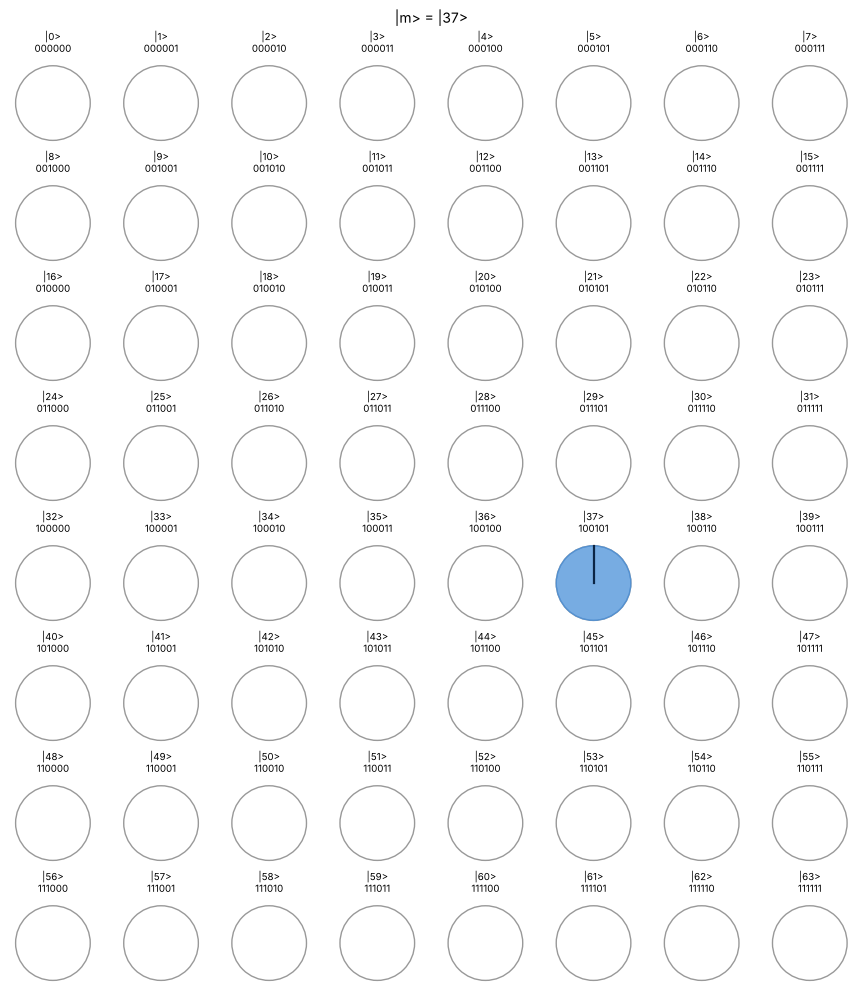

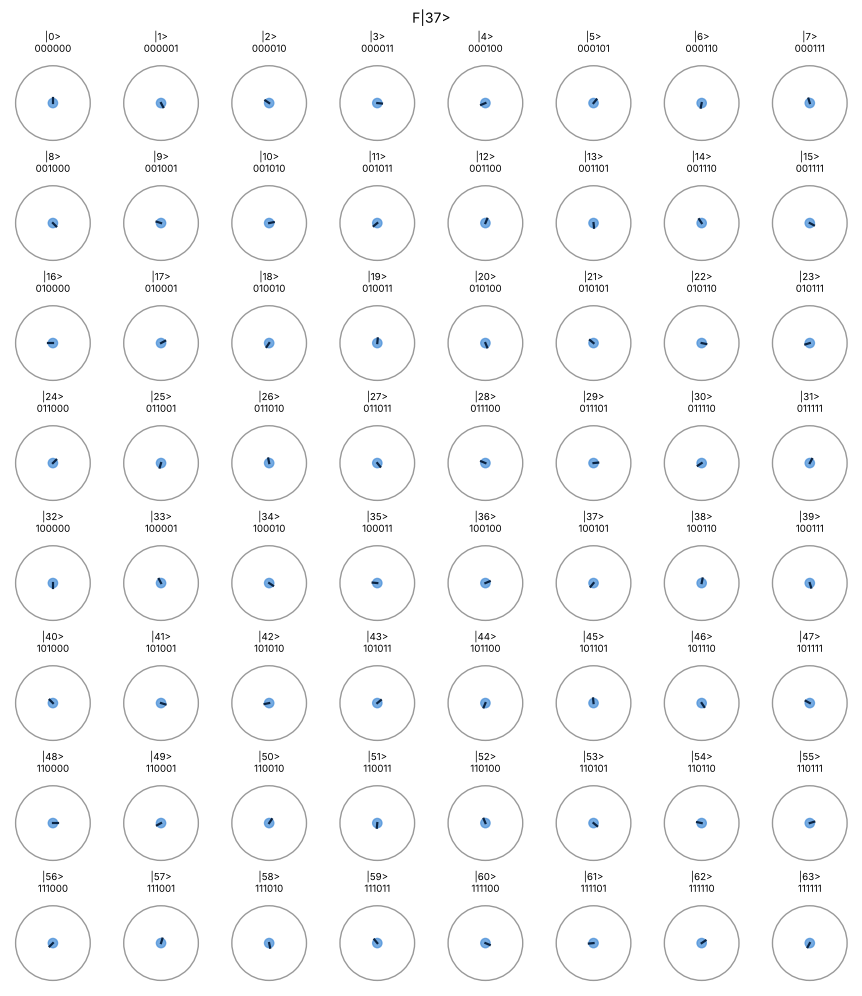

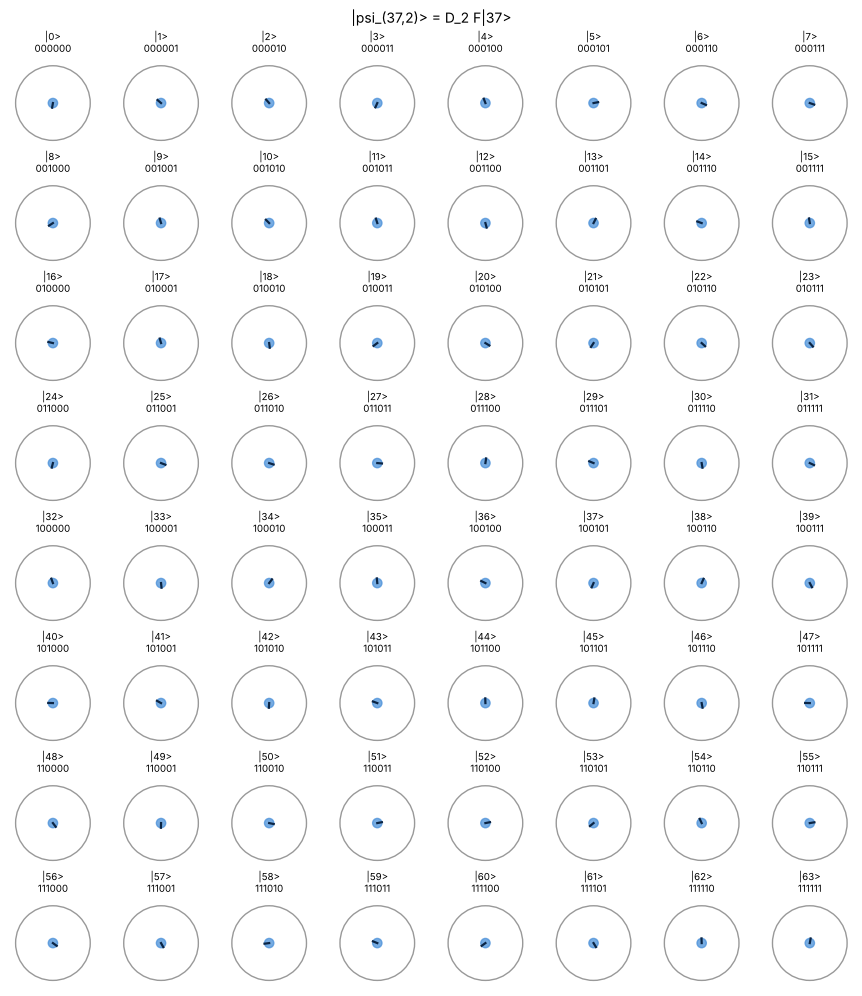

In [6]:
m, k = 37, 2
sv0 = Statevector.from_int(m, d)
sv1 = sv0.evolve(QFTGate(N))
sv2 = sv1.evolve(D_gate(thetas[k]))

plot_circles(sv0, f"|m> = |{m}>")
plot_circles(sv1, f"F|{m}>")
plot_circles(sv2, f"|psi_({m},{k})> = D_{k} F|{m}>")

The same message with every key: the magnitudes are identical in all four, and only the phase pattern depends on the key.

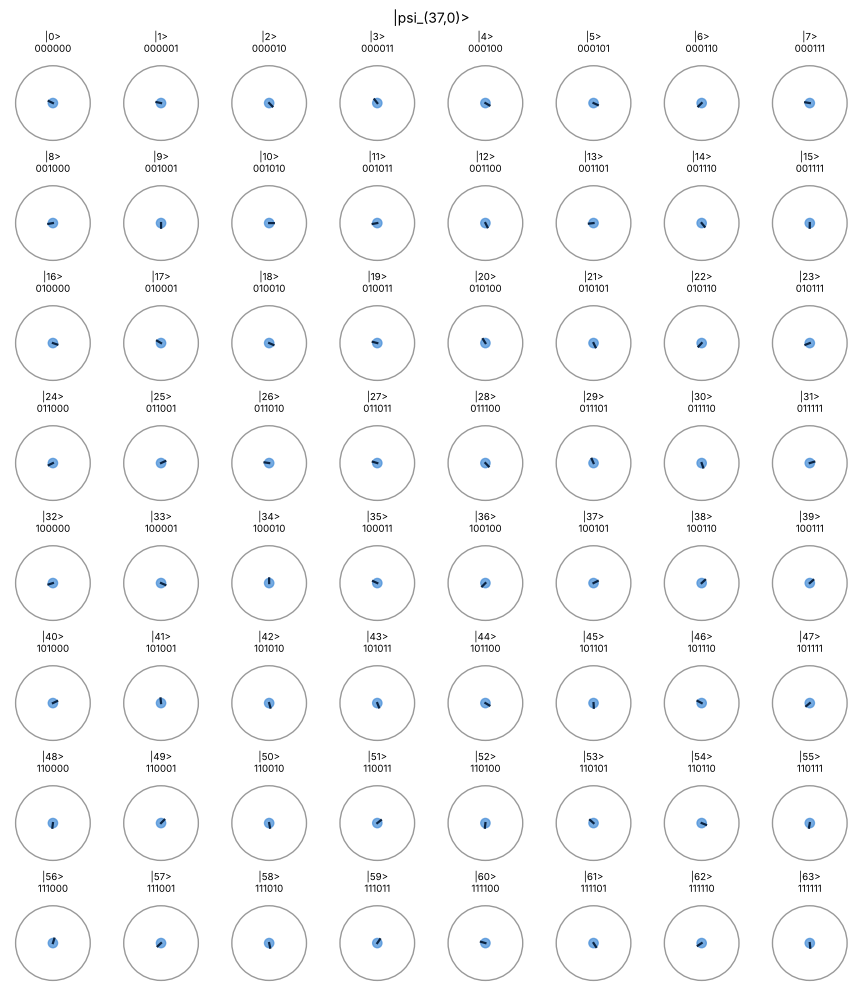

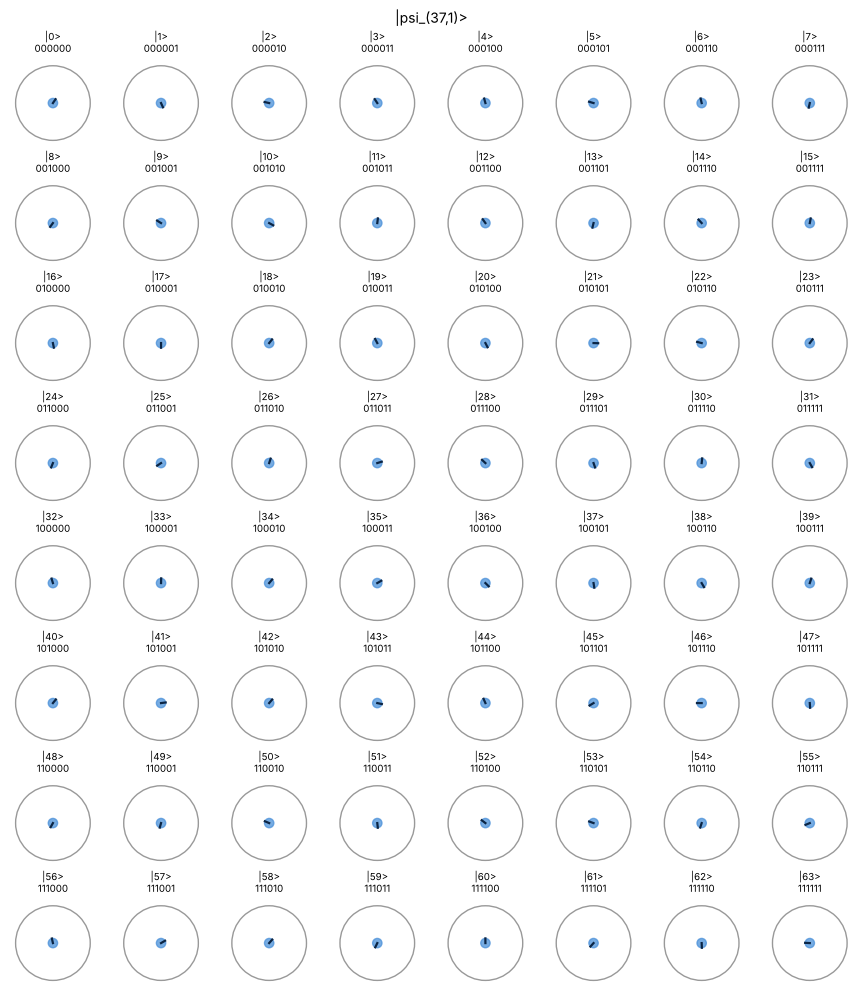

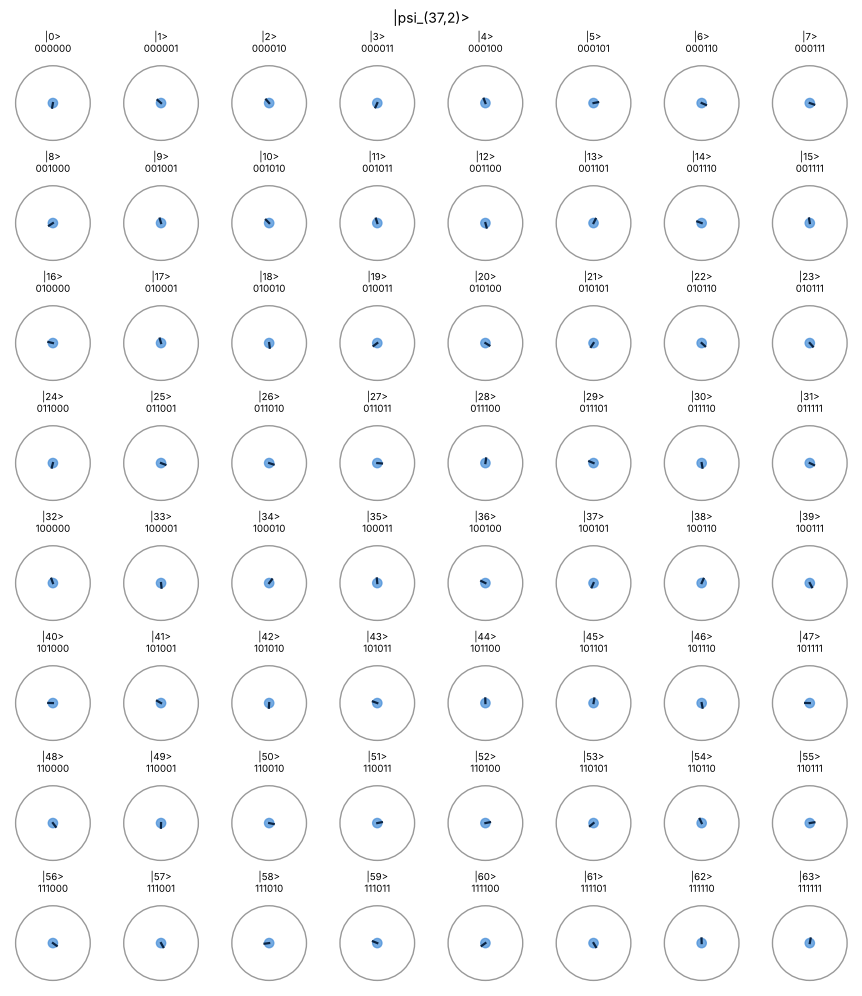

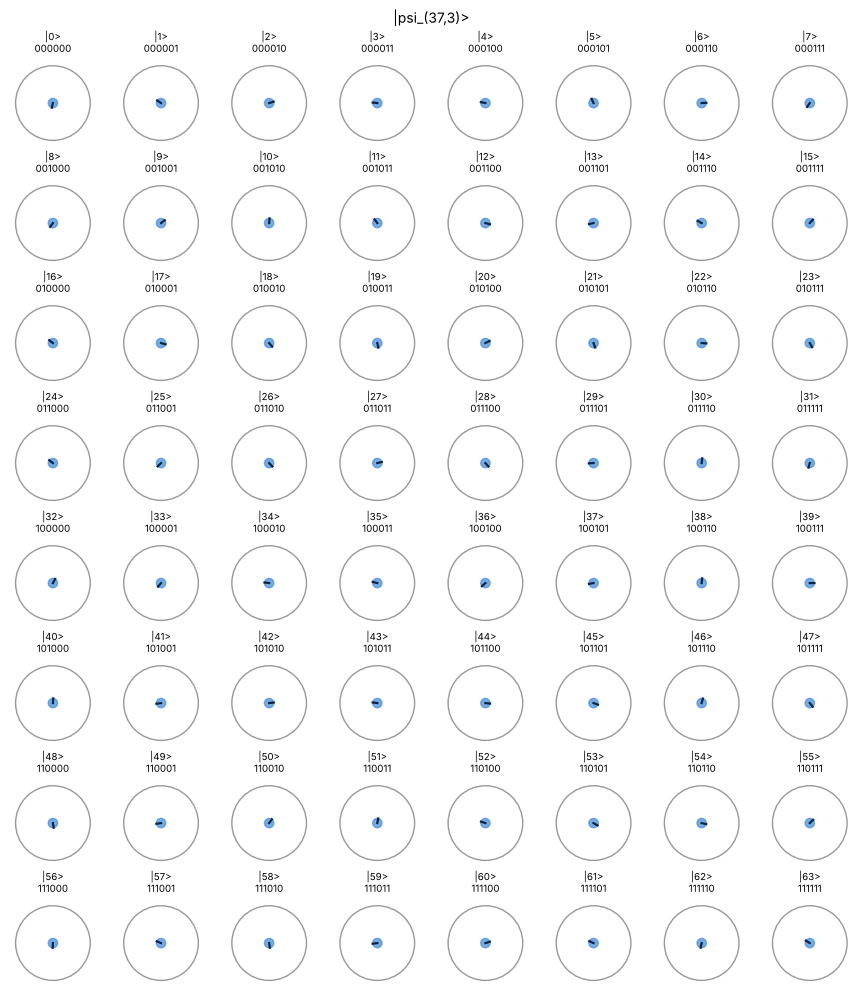

In [7]:
m = 37
for k in keys:
    plot_circles(all_states[k, m], f"|psi_({m},{k})>")

## Property 1: every component has magnitude $1/\sqrt d$

$|e^{i(\cdot)}/\sqrt d|^2 = 1/d$ for every $x$, whatever $m$ and $k$ are. A computational-basis measurement is therefore uniformly random for every message and tells Eve nothing about $m$.

In [8]:
max_dev = np.max(np.abs(np.abs(all_states)**2 - 1 / d))
print("largest |p(x) - 1/d| over all (m, k, x):", max_dev)
assert max_dev < 1e-12

largest |p(x) - 1/d| over all (m, k, x): 5.551115123125783e-17


## Property 2: for a fixed key the codewords are orthonormal

$\langle\psi_{m',k}|\psi_{m,k}\rangle=\langle m'|F^\dagger D_k^\dagger D_kF|m\rangle=\langle m'|m\rangle=\delta_{m'm}$. With the codewords of key $k$ as the columns of $\Psi_k$, the Gram matrix $\Psi_k^\dagger\Psi_k$ is the identity, so Bob, who knows $k$, can distinguish all 64 messages perfectly.

In [9]:
grams = [all_states[k].conj() @ all_states[k].T for k in keys]
for k in keys:
    assert np.allclose(grams[k], np.eye(M))
print("✅ Gram matrix = identity for every key")

✅ Gram matrix = identity for every key


## Property 3: different keys scramble each other

For $k_1\ne k_2$, $O[m',m]=|\langle\psi_{m',k_2}|\psi_{m,k_1}\rangle|^2$. If a codeword of one key were spread perfectly evenly over the codewords of another key, every entry would be $1/M\approx 0.016$. The same-key matrix is the identity. In the cross-key matrix every entry is small: since $O = |F^\dagger D_{k_2}^\dagger D_{k_1} F|^2$ entrywise, each entry depends only on $m-m' \bmod d$ (hence the faint diagonal stripes), and the values scatter around $1/M$ with no large entry, so a codeword of one key looks almost random in the basis of another.

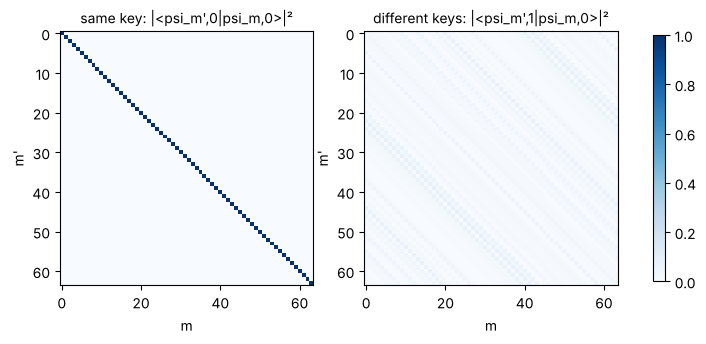

cross-key mean = 0.0156 (1/M = 0.0156),  max = 0.072


In [10]:
k1, k2 = 0, 1
same = np.abs(grams[k1])**2
O = np.abs(all_states[k2].conj() @ all_states[k1].T)**2

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, mat, title in ((axes[0], same, f"same key: |<psi_m',{k1}|psi_m,{k1}>|²"),
                       (axes[1], O, f"different keys: |<psi_m',{k2}|psi_m,{k1}>|²")):
    im = ax.imshow(mat, vmin=0, vmax=1, cmap="Blues")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("m"); ax.set_ylabel("m'")
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

print(f"cross-key mean = {O.mean():.4f} (1/M = {1/M:.4f}),  max = {O.max():.3f}")

## The order matters: $D_kF$, not $FD_k$

On a basis state a diagonal operator is only a global phase, $D_k|m\rangle=e^{i\theta_{k,m}}|m\rangle$, so $FD_k|m\rangle=e^{i\theta_{k,m}}F|m\rangle$ is physically identical to the unlocked $F|m\rangle$. The QFT must come first to spread $|m\rangle$ over all basis states, so that every key phase acts on something.

In [11]:
for k in keys:
    for m in messages:
        sv_m = Statevector.from_int(m, d)
        sv_F = sv_m.evolve(QFTGate(N))
        assert sv_m.evolve(D_gate(thetas[k])).evolve(QFTGate(N)).equiv(sv_F)      # F D_k |m> ~ F|m>
        assert not Statevector(all_states[k, m]).equiv(sv_F)                      # D_k F |m> differs

print("✅ for every (m, k): F D_k|m> equals F|m> up to a global phase, D_k F|m> does not")

✅ for every (m, k): F D_k|m> equals F|m> up to a global phase, D_k F|m> does not


## Eve's view: an ensemble of codewords

Eve knows the protocol and the codebook but not $k$, so for message $m$ she holds one of the $K$ codewords with probability $1/K$ each:

$$\rho_m=\frac1K\sum_{k}|\psi_{m,k}\rangle\langle\psi_{m,k}| .$$

Its purity is close to $1/K$ (an equal mix of $K$ almost-orthogonal states), its computational-basis distribution is uniform, and applying the public $F^\dagger$ gives her $m$ with probability only slightly above $1/M$.

In [12]:
m = 37
rho = DensityMatrix(sum(np.outer(all_states[k, m], all_states[k, m].conj()) for k in keys) / K)
rho_arr = rho.data

p_after_Fdag = np.real(rho.evolve(QFTGate(N).inverse()).data[m, m])

print(f"trace            = {np.real(np.trace(rho_arr)):.6f}")
print(f"purity Tr(rho^2) = {np.real(np.trace(rho_arr @ rho_arr)):.4f}   (1/K = {1/K})")
print(f"computational-basis probabilities: min {np.real(np.diag(rho_arr)).min():.6f}, "
      f"max {np.real(np.diag(rho_arr)).max():.6f}   (1/d = {1/d:.6f})")
print(f"P(m = {m}) after F^dagger = {p_after_Fdag:.4f}   (1/M = {1/M:.4f}, with the key: 1)")

trace            = 1.000000
purity Tr(rho^2) = 0.2720   (1/K = 0.25)
computational-basis probabilities: min 0.015625, max 0.015625   (1/d = 0.015625)
P(m = 37) after F^dagger = 0.0243   (1/M = 0.0156, with the key: 1)


## Test set

Every message–key pair is recorded with its locked state, so the correct decoding result is always known for Task 5.

In [13]:
experiments = [{"m": m, "k": k, "state": all_states[k, m]} for m in messages for k in keys]
np.savez("locked_states.npz", all_states=all_states, thetas=thetas, K=K, N=N, seed=SEED, mode=MODE)
print(len(experiments), "experiments,  all_states.shape =", all_states.shape)

256 experiments,  all_states.shape = (4, 64, 64)
